# Wave IQ Member 03 model development

**Group 30 · Member 03 · Regression training and integration**

Train **Ridge Regression, Decision Tree Regression and Random Forest Regression**.
Keep **DummyRegressor** as a baseline. Select feature variants and hyperparameters
using order-family cross-validation, then evaluate the frozen models on the
reserved test orders. Save complete pipelines that accept raw planning inputs.

The target is the supplied numeric **Rejection** value. Its physical unit and the
event represented by each summary row remain unverified. This is a reproducible
research prototype. The submitted results are modest; they are not a claim of
perfect prediction. Read `README.md` and `reports/RESULTS.md`.

In Colab, upload this notebook, start a fresh runtime and choose **Run all**.
When prompted, upload **Wave-IQ-Member03.zip**. It contains the code, data and
saved run. Source modules are included so your group can inspect every step.

In [1]:
from pathlib import Path, PurePosixPath
import io
import os
import sys
import zipfile

try:
    from google.colab import files as colab_files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

candidates = [Path.cwd(), Path.cwd() / "member03", Path("/content/member03")]
candidates += [parent / "member03" for parent in list(Path.cwd().parents)[:3]]
ROOT = next((path.resolve() for path in candidates
             if (path / "src/waveiq/training.py").is_file()), None)

if ROOT is None and IN_COLAB:
    print("Upload Wave-IQ-Member03.zip, containing the member03 project folder.")
    uploads = colab_files.upload()
    archive_name = next((name for name in uploads if name.lower().endswith(".zip")), None)
    if archive_name is None:
        raise ValueError("Upload the complete project ZIP, not only the CSV or notebook.")
    destination = Path.cwd().resolve()
    with zipfile.ZipFile(io.BytesIO(uploads[archive_name])) as archive:
        members = archive.infolist()
        if len(members) > 200 or sum(item.file_size for item in members) > 150 * 1024**2:
            raise ValueError("Unexpected archive size. Use the supplied Member 03 project ZIP.")
        for item in members:
            relative = PurePosixPath(item.filename.replace("\\", "/"))
            if relative.is_absolute() or ".." in relative.parts or not relative.parts or relative.parts[0] != "member03":
                raise ValueError("Archive must contain only the member03 folder with relative paths.")
            target = destination.joinpath(*relative.parts).resolve()
            target.relative_to(destination / "member03")
            if item.is_dir():
                target.mkdir(parents=True, exist_ok=True)
            else:
                target.parent.mkdir(parents=True, exist_ok=True)
                target.write_bytes(archive.read(item))
    ROOT = destination / "member03"

if ROOT is None:
    raise FileNotFoundError("Open this notebook from the complete member03 folder, or use Colab and upload the project ZIP.")
os.chdir(ROOT)
print("Project folder ready:", ROOT.name)

Project folder ready: member03


## Install the recorded environment

The versions are pinned for consistent pipeline serialization. In Colab, the
cell installs missing or different versions before numerical imports. If a
different NumPy, pandas or scikit-learn is already loaded, restart the session
after installation and run again. A fresh runtime avoids that extra step.

In [2]:
import importlib.metadata as metadata
import subprocess

requirements = {}
for filename in ["requirements.txt"]:
    for line in (ROOT / filename).read_text().splitlines():
        if "==" in line and not line.lstrip().startswith("#"):
            name, version = line.strip().split("==", 1)
            requirements[name] = version
changes = []
for name, wanted in requirements.items():
    try:
        installed = metadata.version(name)
    except metadata.PackageNotFoundError:
        installed = None
    if installed != wanted:
        changes.append(name)
module_names = {"scikit-learn": "sklearn", "numpy": "numpy", "pandas": "pandas", "scipy": "scipy"}
preloaded_changed = any(module_names.get(name, name) in sys.modules for name in changes)
if changes:
    if not IN_COLAB:
        raise RuntimeError("Install requirements.txt in your Python environment before running this notebook.")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-r", str(ROOT / "requirements.txt")])
    if preloaded_changed:
        raise RuntimeError("Pinned packages installed. Restart the Colab session, then run all cells again.")
print("Pinned dependency versions are available.")

Pinned dependency versions are available.


In [3]:
sys.path.insert(0, str(ROOT / "src"))
import inspect
import json
import numpy as np
import pandas as pd
import sklearn
from scipy.sparse import issparse
from IPython.display import Code, Image, Markdown, display
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline

from waveiq.data import GROUP, TARGET, prepare_data
from waveiq.features import RAW_FEATURES, VARIANTS, engineer_features, feature_lists
from waveiq.training import DEFAULT_CONFIG, MAIN_MODELS, model_pipeline, parameter_spaces, run_training
from waveiq.inference import load_predictor, predict_frame
from waveiq.plots import create_plots

print("pandas:", pd.__version__, "NumPy:", np.__version__, "scikit-learn:", sklearn.__version__)
config = DEFAULT_CONFIG.copy()

pandas: 2.2.3 NumPy: 2.2.6 scikit-learn: 1.6.1


## Check the upstream handover

Member 01's newer notebook removes TOTAL records, but the supplied EDA handover
largely follows their summary targets. It also retains 10,940 identical exported
rows. Member 02 explicitly marks its output provisional and leaves four feature
candidates. Its supplied notebook has no correlation calculation.

For this run, keep the supplied Rejection values, count each exact 16-column
export row once, and remove labels without a numeric order identifier. These
are explicit assumptions rather than a newly invented aggregation of targets.
The original rows and all exclusion reasons remain available for review.

In [4]:
prepared = prepare_data(
    ROOT / config["data_path"], seed=config["random_state"],
    test_size=config["test_size"], expected_sha256=config["expected_source_sha256"],
)
display(pd.DataFrame({"Check": [
    "Supplied rows", "Supplied columns", "Missing cells", "Exact duplicate occurrences removed",
    "Distinct non-order placeholders removed", "Development rows", "Test rows", "Purged related rows"
], "Value": [prepared.audit[key] for key in [
    "source_rows", "source_columns", "source_missing_cells", "exact_duplicate_rows_removed",
    "unique_placeholder_rows_removed", "development_rows", "test_rows", "purged_alias_rows"
]]}))
display(prepared.source.head(3))

,Check,Value
0,Supplied rows,22010
1,Supplied columns,16
2,Missing cells,0
3,Exact duplicate occurrences removed,10940
4,Distinct non-order placeholders removed,14
5,Development rows,3365
6,Test rows,2308
7,Purged related rows,5383


,ID,Month,Construction,Req_Finish_Fabrics,Fabric_Allowance,Rec_Beam_length(yds),Shrink_allow,Previous_pdn,Req_grey_fabric,Req_beam_length(yds),Total_Pdn(yds),Rejection,warp_count,weft_count,epi,ppi
0,12207-8,January,40+40/2/40/110x80,31300.0,6.0,38286.936,12.5,26717,33297.872340,34797.651103,27646.0,285,40,80.0,110,80
1,12228-1,January,40x40/110x90,10450.0,7.0,13057.584,14.5,11019,11236.559140,12017.350432,11019.0,39,40,40.0,110,90
2,12249-6(B),January,40x40/110x80,900.0,11.5,1902.864,12.5,1528,1016.949153,1062.753843,1528.0,0,40,40.0,110,80


## Preserve the test orders and group related families

Reproduce Member 02's exact-ID split first: seed 42 and 20% of unique IDs.
Then apply a conservative five-digit family rule across suborders and suffixes.
Combined SF IDs link all their stated families. Purge related development rows;
do not reassign them to test. This keeps the original test population separate
from records already explored during EDA.

The grouping is a leakage precaution. The source owner must still confirm
whether these families describe the intended deployment scenario.

In [5]:
dev = prepared.development
test = prepared.test
X, y, groups = dev[RAW_FEATURES], dev[TARGET], dev[GROUP]
assert set(dev[GROUP]).isdisjoint(test[GROUP])
assert set(dev["ID"]).isdisjoint(test["ID"])
folds = list(GroupKFold(n_splits=5).split(X, y, groups))
fold_summary = []
for number, (train_idx, validation_idx) in enumerate(folds, 1):
    training_groups = set(groups.iloc[train_idx])
    validation_groups = set(groups.iloc[validation_idx])
    assert training_groups.isdisjoint(validation_groups)
    assert training_groups.isdisjoint(test[GROUP])
    fold_summary.append({"Fold": number, "Training rows": len(train_idx),
                         "Validation rows": len(validation_idx),
                         "Training families": len(training_groups),
                         "Validation families": len(validation_groups), "Overlap": 0})
display(pd.DataFrame(fold_summary))

,Fold,Training rows,Validation rows,Training families,Validation families,Overlap
0,1,2692,673,141,34,0
1,2,2692,673,140,35,0
2,3,2692,673,140,35,0
3,4,2692,673,140,35,0
4,5,2692,673,139,36,0


## Reuse Member 02 features inside each fold

| Engineered feature | Formula |
| --- | --- |
| Thread_Density | epi + ppi |
| EPI_PPI_Ratio | epi / ppi, with positive denominator |
| Log_Order_Size | log1p(Req_Finish_Fabrics) |
| Fabric_Expansion_Ratio | Req_grey_fabric / Req_Finish_Fabrics |

The four candidates are original, engineered, reduced and compact. Medians,
scaling and one-hot categories are learned only from training rows. Ridge uses
numeric scaling; trees do not require it. The ID, Month, target and production
outcome columns never enter the model's feature matrix.

In [6]:
display(pd.DataFrame([
    {"Candidate": variant, "Features before encoding": len(sum(feature_lists(variant), [])),
     "Names": ", ".join(sum(feature_lists(variant), []))}
    for variant in VARIANTS
]))
display(engineer_features(X.head(3)))

# Demonstrate fold-fitted preprocessing without fitting the final model.
train_idx, validation_idx = folds[0]
preprocessing_demo = Pipeline(model_pipeline("ridge").steps[:2])
training_matrix = preprocessing_demo.fit_transform(X.iloc[train_idx])
validation_matrix = preprocessing_demo.transform(X.iloc[validation_idx])
for matrix in [training_matrix, validation_matrix]:
    assert np.isfinite(matrix.data if issparse(matrix) else matrix).all()
print("First-fold transformed shapes:", training_matrix.shape, validation_matrix.shape)

,Candidate,Features before encoding,Names
0,original,10,"Req_Finish_Fabrics, Fabric_Allowance, Shrink_a..."
1,engineered,14,"Req_Finish_Fabrics, Fabric_Allowance, Shrink_a..."
2,reduced,12,"Req_Finish_Fabrics, Fabric_Allowance, Shrink_a..."
3,compact,10,"Log_Order_Size, Fabric_Allowance, Shrink_allow..."


,Req_Finish_Fabrics,Fabric_Allowance,Shrink_allow,Req_grey_fabric,Req_beam_length(yds),warp_count,weft_count,epi,ppi,Construction,Thread_Density,EPI_PPI_Ratio,Log_Order_Size,Fabric_Expansion_Ratio
0,31300.0,6.0,12.5,33297.872340,34797.651103,40,80.0,110,80,40+40/2/40/110x80,190,1.375000,10.351405,1.063830
1,10450.0,7.0,14.5,11236.559140,12017.350432,40,40.0,110,90,40x40/110x90,200,1.222222,9.254453,1.075269
2,900.0,11.5,12.5,1016.949153,1062.753843,40,40.0,110,80,40x40/110x80,190,1.375000,6.803505,1.129944


First-fold transformed shapes: (2692, 67) (673, 67)


## Implement the baseline and three regressors

| Estimator | Purpose | Main tuning controls |
| --- | --- | --- |
| DummyRegressor median | Constant absolute-error baseline | Fixed, no tuning |
| Ridge | Regularized linear regression | alpha |
| Decision Tree | Nonlinear splits and leaf predictions | depth, leaf size, split size, criterion, pruning |
| Random Forest | Average bootstrap trees | trees, depth, leaf size, feature sampling, row sampling |

The following output shows the actual shared implementation. Complete feature
preprocessing and target transformation are saved with each regressor.

In [7]:
display(Code(inspect.getsource(model_pipeline), language="python"))
model_pipeline("ridge")

def model_pipeline(name: str, seed: int = 42) -> Pipeline:
    if name == "ridge":
        estimator = Ridge(alpha=1.0, solver="lsqr", tol=1e-6)
    elif name == "decision_tree":
        estimator = DecisionTreeRegressor(random_state=seed)
    elif name == "random_forest":
        # Search parallelism is outside the forest; avoid nested CPU oversubscription.
        estimator = RandomForestRegressor(random_state=seed, n_jobs=1)
    elif name == "dummy_median":
        estimator = DummyRegressor(strategy="median")
    else:
        raise ValueError(f"Unknown model: {name}")
    return Pipeline([
        ("features", FeatureBuilder("engineered")),
        ("preprocessing", build_preprocessor(scale_numeric=name == "ridge")),
        ("model", TransformedTargetRegressor(
            regressor=estimator, func=identity_target, inverse_func=nonnegative_identity,
            check_inverse=False,
        )),
    ])

Pipeline(steps=[('features', FeatureBuilder()),
                ('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(keep_empty_features=True,
                                                                                 strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x000002AAF7EA14C0>),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImpute...lue='Missing',
                                                                                 keep_empty_features=True,
                                                                                 strategy='constant')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Construction'])])),
                ('model',
                 TransformedTargetRegressor(check_inverse=False,
                                            func=<function identity_target at 0x000002AAF6F88FE0>,
                                            inverse_func=<function nonnegative_identity at 0x000002AAF6F89080>,
                                            regressor=Ridge(solver='lsqr',
                                                            tol=1e-06)))])

## Tune without looking at test outcomes

The primary score is MAE on the original target scale. RMSE and R² are secondary.
Each regressor compares identity and log1p target settings. Inverse conversion
and a fixed zero lower bound apply before every validation or test score.
These settings do not introduce additional main model families.

There are 72 Ridge settings, 40 sampled tree settings and 32 sampled forest
settings, each using the same five grouped folds. The best setting per family
is refitted on all development rows. Selection is written before test prediction.

In [8]:
from sklearn.model_selection import ParameterGrid
display(pd.DataFrame([
    {"Model": "ridge", "Candidates": len(ParameterGrid(parameter_spaces("ridge"))), "Folds": 5},
    {"Model": "decision_tree", "Candidates": config["decision_tree_iterations"], "Folds": 5},
    {"Model": "random_forest", "Candidates": config["random_forest_iterations"], "Folds": 5},
]))

# True reproduces the complete training run. False inspects the submitted run.
RUN_TRAINING = True
if RUN_TRAINING:
    result = run_training(ROOT)
else:
    print("Inspection mode: reading the submitted artifacts; no retraining is performed.")
    assert (ROOT / "artifacts/selection.json").exists()
_ = create_plots(ROOT)

,Model,Candidates,Folds
0,ridge,72,5
1,decision_tree,40,5
2,random_forest,32,5


Preparing the reviewed handover and preserving the Member 02 test orders...


{
  "source_name": "weaving_rejection_eda_input.csv",
  "source_sha256": "554143538c452416b86c8402cc59d48c288c074c53229d854ad690c6bc29c07f",
  "source_rows": 22010,
  "source_columns": 16,
  "source_missing_cells": 0,
  "exact_duplicate_rows_removed": 10940,
  "placeholder_rows_in_source": 33,
  "unique_placeholder_rows_removed": 14,
  "clean_rows_including_purged": 11056,
  "original_exact_id_development_rows": 17452,
  "original_exact_id_test_rows": 4558,
  "original_exact_id_development_groups": 782,
  "original_exact_id_test_groups": 196,
  "development_rows": 3365,
  "test_rows": 2308,
  "purged_alias_rows": 5383,
  "development_families": 175,
  "test_families": 125,
  "purged_raw_ids": 454,
  "family_overlap_development_test": 0,
  "exact_id_overlap_development_test": 0,
  "split_policy": "preserve_member02_exact_id_test_then_purge_related_development_families",
  "prediction_target": "Rejection",
  "target_unit": "unverified_recorded_amount",
  "observation": "one_distinct_supp

Median baseline CV MAE: 84.3422


Tuning ridge using 5 order-family folds...


ridge: CV MAE=82.8350, log1p target, engineered features (16.7 seconds)


... (2 outputs left out)

Tuning random_forest using 5 order-family folds...


random_forest: CV MAE=82.0220, log1p target, engineered features (97.4 seconds)


Selection frozen: random_forest; now evaluating the untouched test rows.


        model     role       MAE       RMSE        R2  selected_using_development_cv
 dummy_median baseline 46.529029 121.101739 -0.111969                          False
        ridge     main 51.807547 126.476945 -0.212871                          False
decision_tree     main 46.321123 121.517523 -0.119618                          False
random_forest     main 45.248376 120.004015 -0.091902                           True


## Read the frozen comparison

The mean CV scores were used for tuning. The separate test scores estimate
performance after selection under the stated source and grouping assumptions.
Do not change the selection after reading this test table. A negative R² is a
valid result and is not a percentage accuracy score.

In [9]:
cv_results = pd.read_csv(ROOT / "reports/cv_comparison.csv")
test_results = pd.read_csv(ROOT / "reports/holdout_comparison.csv")
selection = json.loads((ROOT / "artifacts/selection.json").read_text())
display(cv_results[["model", "cv_MAE", "cv_MAE_std", "cv_RMSE", "cv_R2", "feature_variant", "target_transform"]].round(3))
display(test_results.round(3))
print("Selected predictor:", selection["selected_predictor"])
print("Best main family:", selection["best_main_model"])

,model,cv_MAE,cv_MAE_std,cv_RMSE,cv_R2,feature_variant,target_transform
0,random_forest,82.022,25.635,232.231,-0.092,engineered,log1p
1,decision_tree,82.597,24.530,230.268,-0.079,original,log1p
2,ridge,82.835,25.360,231.652,-0.084,engineered,log1p
3,dummy_median,84.342,26.380,237.786,-0.144,NaN,NaN


,model,role,MAE,RMSE,R2,selected_using_development_cv
0,dummy_median,baseline,46.529,121.102,-0.112,False
1,ridge,main,51.808,126.477,-0.213,False
2,decision_tree,main,46.321,121.518,-0.120,False
3,random_forest,main,45.248,120.004,-0.092,True


Selected predictor: random_forest
Best main family: random_forest


## Inspect errors and generalization

The comparison includes the median baseline. Actual versus predicted values are shown on original and log1p scales, so large underestimates remain visible. The training/validation comparison helps identify overfitting.

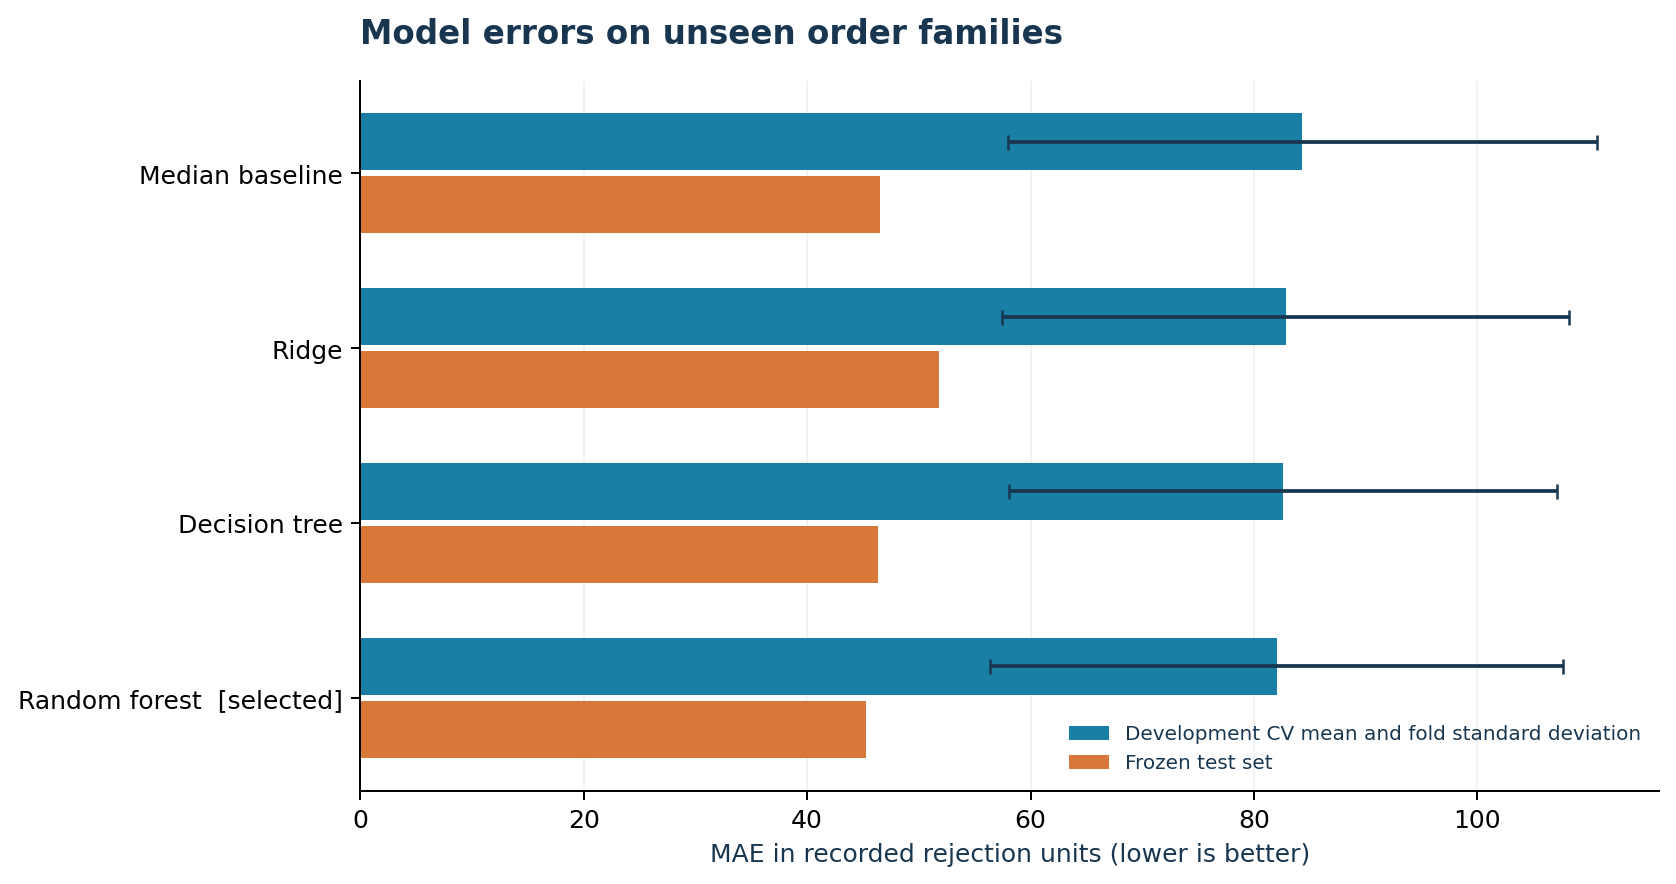

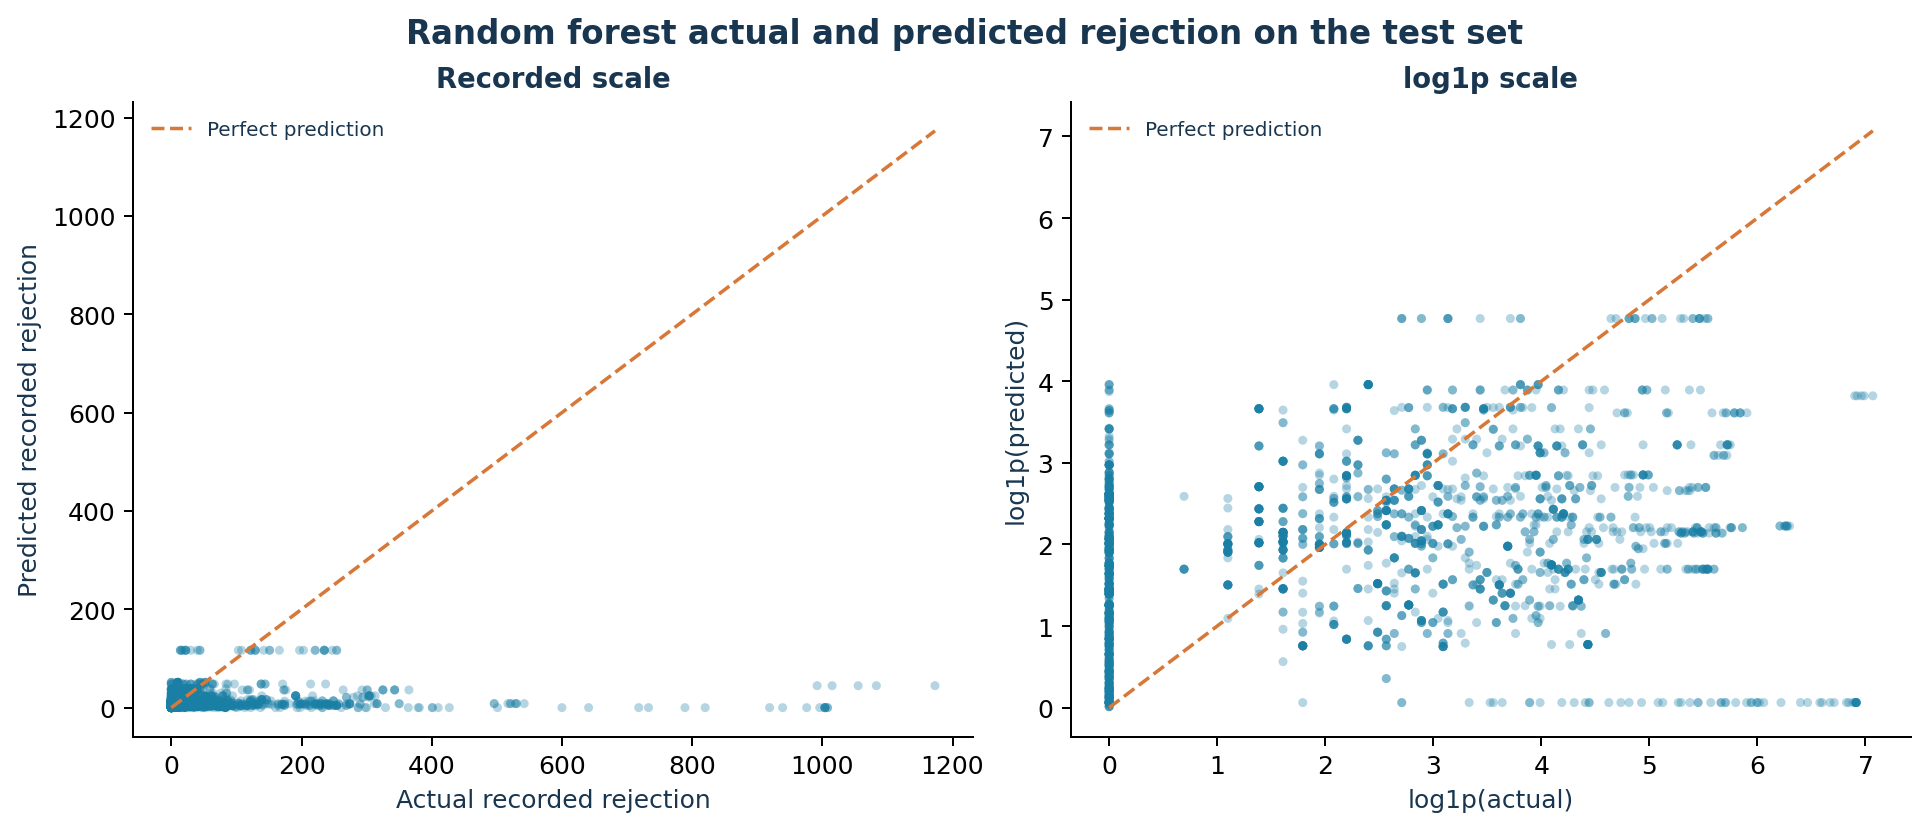

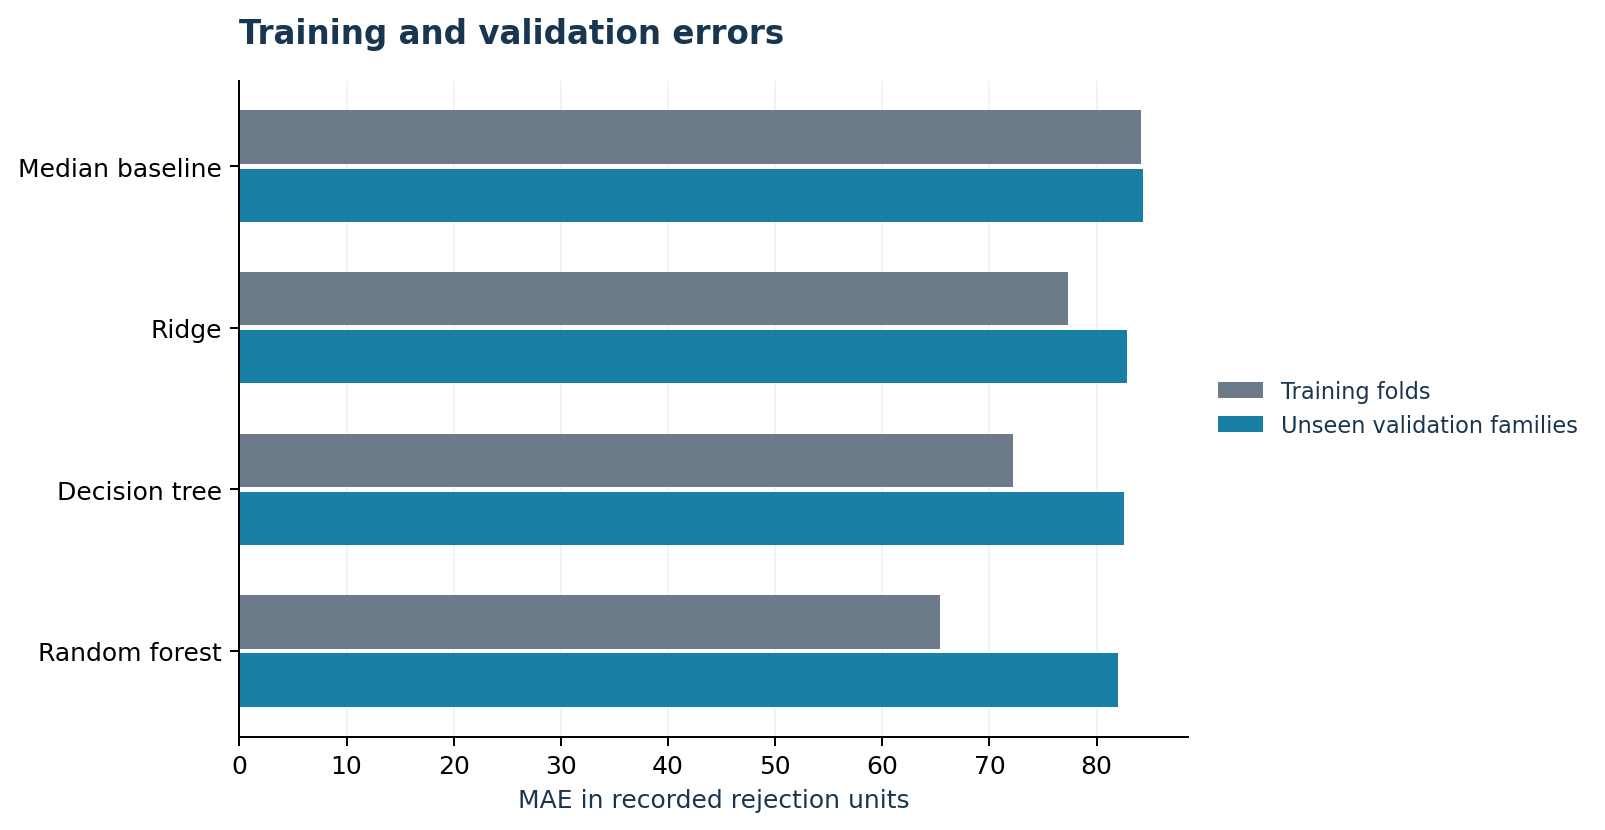

In [10]:
for filename in ["model_comparison.png", "actual_vs_predicted.png", "training_validation_gap.png"]:
    display(Image(filename=str(ROOT / "reports/figures" / filename)))

## Verify complete saved pipelines and final features

The three main models and separate baseline are complete importable pipelines. Their package versions, best parameters and feature lists accompany them. Test and purged records are not included in saved fits.

In [11]:
display(pd.DataFrame([
    {"Model": name, "File": f"artifacts/{name}.joblib",
     "Bytes": (ROOT / f"artifacts/{name}.joblib").stat().st_size,
     "SHA256": selection["model_sha256"][name]}
    for name in ["dummy_median", *MAIN_MODELS]
]))
display(pd.read_csv(ROOT / "reports/final_feature_list.csv"))
model, model_name = load_predictor(ROOT)
saved = pd.read_csv(ROOT / "reports/holdout_predictions.csv")
np.testing.assert_allclose(model.predict(test[RAW_FEATURES]), saved[f"predicted_{model_name}"], rtol=1e-10)
print("Reloaded pipeline matches all recorded test predictions.")

,Model,File,Bytes,SHA256
0,dummy_median,artifacts/dummy_median.joblib,2245,95bae34c681cb529c336da3c5290d6ab1098ef66023c12...
1,ridge,artifacts/ridge.joblib,3588,ff022686dce915be7a547d093ea572ea59ad89c35647df...
2,decision_tree,artifacts/decision_tree.joblib,3702,17b6cf0c34ba40a2694d151c3944ed5e13a74d2864db86...
3,random_forest,artifacts/random_forest.joblib,854131,559e00cc2909934ad0d19e7536c56d1cdb4210755f4a9d...


,model,feature,feature_variant
0,ridge,Req_Finish_Fabrics,engineered
1,ridge,Fabric_Allowance,engineered
2,ridge,Shrink_allow,engineered
3,ridge,Req_grey_fabric,engineered
4,ridge,Req_beam_length(yds),engineered
5,ridge,warp_count,engineered
6,ridge,weft_count,engineered
7,ridge,epi,engineered
8,ridge,ppi,engineered
9,ridge,Thread_Density,engineered


Reloaded pipeline matches all recorded test predictions.


## Demonstrate prediction from raw planning inputs

These examples come from the development population. No target, ID or production
outcome is needed. Edit the raw values to try another planned fabric. The output
unit remains the source's unverified recorded amount, not a percentage.

In [12]:
sample = dev[RAW_FEATURES].drop_duplicates().head(3).copy()
display(sample)

# Edit values here before rerunning this cell, for example:
# sample.loc[0, "Req_Finish_Fabrics"] = 5000
# Keep the related planned quantities internally consistent for a meaningful scenario.
demo = predict_frame(sample, ROOT)
display(demo[["Predicted_Rejection", "Model", "Prediction_Unit"]].round(3))
demo.to_csv(ROOT / "reports/demo_predictions.csv", index=False)

,Req_Finish_Fabrics,Fabric_Allowance,Shrink_allow,Req_grey_fabric,Req_beam_length(yds),warp_count,weft_count,epi,ppi,Construction
0,31300.0,6.0,12.5,33297.872340,34797.651103,40,80.0,110,80,40+40/2/40/110x80
1,10450.0,7.0,14.5,11236.559140,12017.350432,40,40.0,110,90,40x40/110x90
2,900.0,11.5,12.5,1016.949153,1062.753843,40,40.0,110,80,40x40/110x80


,Predicted_Rejection,Model,Prediction_Unit
0,281.725,random_forest,unverified_recorded_amount
1,13.789,random_forest,unverified_recorded_amount
2,6.417,random_forest,unverified_recorded_amount


## Check the required deliverables

Verify that all four saved pipelines load, return finite nonnegative predictions and agree with the recorded test predictions. Confirm the development and test families remain separate.

In [13]:
assert set(dev[GROUP]).isdisjoint(test[GROUP])
for name in ["dummy_median", *MAIN_MODELS]:
    fitted, _ = load_predictor(ROOT, name)
    prediction = fitted.predict(test[RAW_FEATURES])
    assert np.isfinite(prediction).all() and (prediction >= 0).all()
    np.testing.assert_allclose(prediction, saved[f"predicted_{name}"], rtol=1e-10)
assert len(pd.read_csv(ROOT / "reports/search_results/ridge.csv")) == 72
assert len(pd.read_csv(ROOT / "reports/search_results/decision_tree.csv")) == 40
assert len(pd.read_csv(ROOT / "reports/search_results/random_forest.csv")) == 32
print("All Member 03 models, split boundaries and recorded predictions passed the checks.")

All Member 03 models, split boundaries and recorded predictions passed the checks.


## Save results for Member 04

The artifacts folder contains complete saved models. The reports folder contains comparison tables, test predictions, tuning scores and graphs. Member 04 can evaluate these frozen models and use the prediction example above.

Any substantive model redesign after viewing these test results needs a fresh evaluation protocol. The group still needs to confirm the target unit, summary-row event definition and duplicate semantics.

In [14]:
from waveiq.reporting import write_results
write_results(ROOT)

if IN_COLAB:
    archive_path = ROOT.parent / "Member03_Run_Artifacts.zip"
    with zipfile.ZipFile(archive_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
        for folder in ["artifacts", "reports", "data/processed"]:
            for path in sorted((ROOT / folder).rglob("*")):
                if path.is_file() and "__pycache__" not in path.parts:
                    archive.write(path, path.relative_to(ROOT).as_posix())
    colab_files.download(str(archive_path))
else:
    print("Run outputs are saved in artifacts/, reports/ and data/processed/.")

Run outputs are saved in artifacts/, reports/ and data/processed/.


## Explain your contribution

Member 02 supplied the candidate feature formulas and initial EDA. Member 03
implemented explicit training repairs, stricter grouped validation, the three
regression models, hyperparameter tuning, frozen selection, complete saved
pipelines, verification and the integration interface. Explain the modest
baseline comparison and negative R² candidly. Use the model explanations and results above for your four-minute presentation and viva preparation.